# QuickBite: know your diners

**MAIB in-class ML challenge: segmentation, market-basket analysis and reorder prediction**

QuickBite's management asked three questions: *who are our diners, what do they order together, and who is about to stop ordering?* This notebook answers each one with the data, then saves the models so the provided `app.py` dashboard can use them.

| Part | Question | Method |
|---|---|---|
| 0 | Can we trust the data? | Exploration and data-quality checks |
| 1 | Who are our diners? | K-Means clustering (elbow + silhouette) |
| 2 | What do they order together? | Apriori association rules, overall and per segment |
| 3 | Who will come back? | Reorder classifier, chosen by the cost of each mistake |
| 4 | Make it usable | `food_models.joblib` + test with `app.py` |
| 5 | What else does the data say? | F1 one rule nearly matches the model · F2 each segment has its own churn clock · F5 segments are real |
| 6 | So what? | Business takeaway |

Every number below is computed from `diners.csv` and `orders.csv`. Throughout, I explain results in plain business language.

In [1]:
import inspect, warnings, hashlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, adjusted_rand_score, accuracy_score, confusion_matrix,
                             roc_auc_score, roc_curve, recall_score, precision_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import mlxtend, sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# One palette for every chart (matches the dashboard)
INK, ACCENT, RED, MUTED = "#0F3D3E", "#F2994A", "#D1495B", "#8A9BA3"
SEG_COLORS = {"Families": "#F2994A", "Premium foodies": "#7B2D5B", "Budget students": "#6A994E"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#C9D3D8", "axes.labelcolor": INK, "xtick.color": INK,
                     "ytick.color": INK, "axes.titleweight": "bold", "axes.titlecolor": INK,
                     "font.size": 10})
RANDOM_STATE = 42
print("scikit-learn", sklearn.__version__, "| mlxtend", mlxtend.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | mlxtend 0.25.0 | pandas 3.0.5


In [2]:
diners = pd.read_csv("diners.csv")
orders = pd.read_csv("orders.csv")

FEATURES = ['orders_per_month', 'avg_order_value', 'avg_items_per_order', 'days_since_last_order', 'discount_rate']
CLF_INPUTS = FEATURES + ['age', 'total_spend']          # the 7 inputs app.py sends, in this order
TARGET = 'reordered'
diners.head()

,diner_id,age,orders_per_month,avg_order_value,avg_items_per_order,days_since_last_order,discount_rate,total_spend,reordered
0,D1293,36,3,156.82,7,26,0.27,504.96,0
1,D1283,37,3,164.51,7,24,0.16,439.86,0
2,D1034,24,16,44.68,2,0,0.73,676.57,1
3,D1380,36,9,99.45,3,9,0.13,866.99,1
4,D1430,34,8,88.04,4,11,0.10,728.98,1


## Part 0: Explore the data

Before modelling anything, I check the size of each table, look for missing values, see how balanced the target is and work out the score a model has to beat.

In [3]:
print("diners.csv :", diners.shape, "| orders.csv :", orders.shape)
print("Missing values  diners:", int(diners.isna().sum().sum()), " orders:", int(orders.isna().sum().sum()))
print("Duplicate diner IDs:", int(diners.diner_id.duplicated().sum()),
      "| duplicate item rows inside a basket:", int(orders.duplicated(['order_id', 'item']).sum()))
print("Unique baskets (order_id):", orders.order_id.nunique(), "| diners with orders:", orders.diner_id.nunique(),
      "| menu items:", orders.item.nunique())
diners.describe().T.round(2)

diners.csv : (480, 9) | orders.csv : (4924, 3)
Missing values  diners: 0  orders: 0
Duplicate diner IDs: 0 | duplicate item rows inside a basket: 0
Unique baskets (order_id): 1980 | diners with orders: 480 | menu items: 17


,count,mean,std,min,25%,50%,75%,max
age,480.0,30.68,8.65,9.00,23.00,31.00,38.00,52.00
orders_per_month,480.0,9.04,4.45,1.00,5.00,9.00,12.00,20.00
avg_order_value,480.0,98.08,57.16,29.50,43.70,90.58,157.22,218.66
avg_items_per_order,480.0,3.51,1.87,1.00,2.00,3.00,5.00,9.00
days_since_last_order,480.0,10.81,7.12,0.00,5.00,9.00,15.00,34.00
discount_rate,480.0,0.38,0.23,0.00,0.16,0.36,0.60,0.86
total_spend,480.0,664.76,222.82,134.04,510.54,638.92,789.31,1490.17
reordered,480.0,0.60,0.49,0.00,0.00,1.00,1.00,1.00


reordered
reordered (1)    288
churned (0)      192

Majority-class baseline: always predict 'reordered' -> 60.0% accuracy


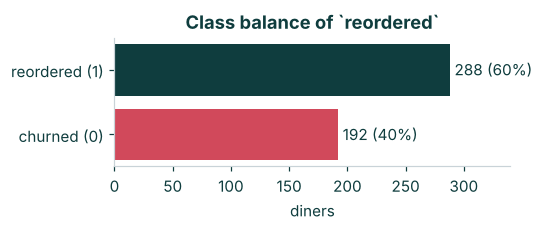

In [4]:
balance = diners[TARGET].value_counts().rename({1: 'reordered (1)', 0: 'churned (0)'})
baseline = diners[TARGET].value_counts(normalize=True).max()
print(balance.to_string())
print(f"\nMajority-class baseline: always predict 'reordered' -> {baseline:.1%} accuracy")

fig, ax = plt.subplots(figsize=(5, 2.2))
ax.barh(['churned (0)', 'reordered (1)'], [balance['churned (0)'], balance['reordered (1)']], color=[RED, INK])
for i, v in enumerate([balance['churned (0)'], balance['reordered (1)']]):
    ax.text(v + 4, i, f"{v} ({v/len(diners):.0%})", va='center', color=INK)
ax.set_xlim(0, 340); ax.set_title("Class balance of `reordered`"); ax.set_xlabel("diners")
plt.tight_layout(); plt.show()

**Reading it:** 60% of diners reordered and 40% churned. A model that always says "will reorder" is already right 60% of the time, so that is the bar to beat. Accuracy alone can also flatter a model that ignores churners, which is why Part 3 also looks at how many churners each model catches.

### Data-quality checks

Three things in the data don't add up. None of them stops the analysis, but they affect how the results should be read.

1) Diners under 18: 20 (ages 9-17); youngest diner is 9. app.py's age slider starts at 18.


2) Basket size in orders.csv: 1-4 items (mean 2.49); avg_items_per_order in diners.csv: 1-9 (mean 3.51).
   Correlation between the two per diner: 0.52; only 38% of diners match when rounded. Each diner has 2-6 baskets in orders.csv.
3) total_spend / (orders_per_month x avg_order_value): mean 1.002, range 0.85-1.15. So total_spend is about ONE month of spending, not a lifetime total.


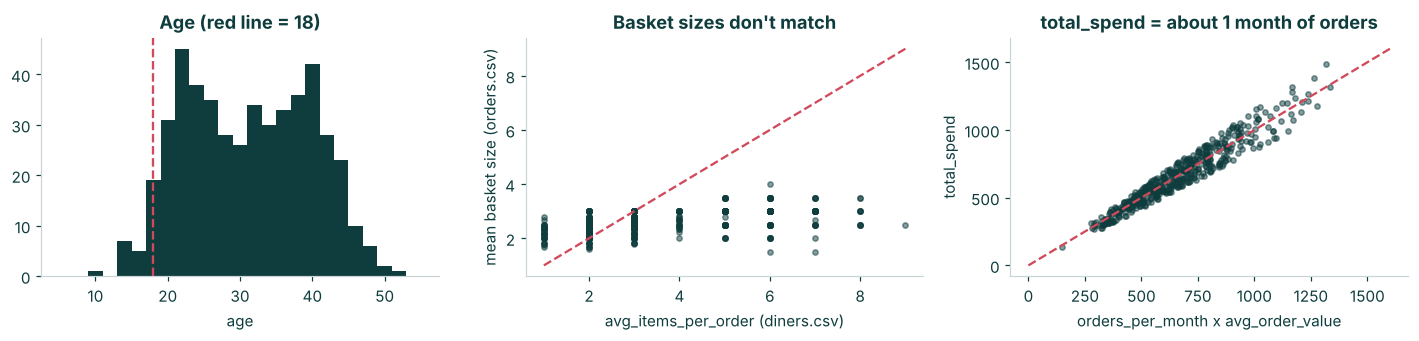

In [5]:
# 1) Diners under 18
under18 = diners[diners.age < 18]
print(f"1) Diners under 18: {len(under18)} (ages {under18.age.min()}-{under18.age.max()}); "
      f"youngest diner is {diners.age.min()}. app.py's age slider starts at 18.")

# 2) Basket sizes in orders.csv vs avg_items_per_order in diners.csv
basket_size = orders.groupby('order_id').size()
per_diner = (orders.groupby('order_id').agg(diner_id=('diner_id', 'first'), n_items=('item', 'size'))
             .groupby('diner_id').agg(baskets=('n_items', 'size'), mean_basket=('n_items', 'mean')))
chk = diners.set_index('diner_id').join(per_diner)
print(f"2) Basket size in orders.csv: {basket_size.min()}-{basket_size.max()} items (mean {basket_size.mean():.2f}); "
      f"avg_items_per_order in diners.csv: {diners.avg_items_per_order.min()}-{diners.avg_items_per_order.max()} "
      f"(mean {diners.avg_items_per_order.mean():.2f}).")
print(f"   Correlation between the two per diner: {chk[['avg_items_per_order','mean_basket']].corr().iloc[0,1]:.2f}; "
      f"only {(chk.avg_items_per_order.round() == chk.mean_basket.round()).mean():.0%} of diners match when rounded. "
      f"Each diner has {chk.baskets.min()}-{chk.baskets.max()} baskets in orders.csv.")

# 3) total_spend vs orders_per_month x avg_order_value
ratio = diners.total_spend / (diners.orders_per_month * diners.avg_order_value)
print(f"3) total_spend / (orders_per_month x avg_order_value): mean {ratio.mean():.3f}, "
      f"range {ratio.min():.2f}-{ratio.max():.2f}. So total_spend is about ONE month of spending, not a lifetime total.")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(diners.age, bins=range(5, 56, 2), color=INK); axes[0].axvline(18, color=RED, ls='--')
axes[0].set_title("Age (red line = 18)"); axes[0].set_xlabel("age")
axes[1].scatter(chk.avg_items_per_order, chk.mean_basket, s=12, alpha=.5, color=INK)
axes[1].plot([1, 9], [1, 9], color=RED, ls='--'); axes[1].set_xlabel("avg_items_per_order (diners.csv)")
axes[1].set_ylabel("mean basket size (orders.csv)"); axes[1].set_title("Basket sizes don't match")
axes[2].scatter(diners.orders_per_month * diners.avg_order_value, diners.total_spend, s=12, alpha=.5, color=INK)
lim = [0, 1600]; axes[2].plot(lim, lim, color=RED, ls='--')
axes[2].set_xlabel("orders_per_month x avg_order_value"); axes[2].set_ylabel("total_spend")
axes[2].set_title("total_spend = about 1 month of orders")
plt.tight_layout(); plt.show()

**What this means:**
1. **20 diners are under 18, and the youngest is 9.** These are probably data-entry errors or shared family accounts. I keep them because dropping 4% of rows wouldn't change the segments, but QuickBite should check its age data. All 20 end up in the student segment.
2. **Basket sizes don't match.** `orders.csv` baskets hold 1–4 items, while `avg_items_per_order` runs up to 9. The two only partly agree (correlation about 0.5). `orders.csv` is most likely a *sample* of each diner's orders, so the basket rules describe item *pairings* well but understate basket sizes.
3. **`total_spend` is about one month of spending**, not a lifetime total (it is within ±15% of orders/month × order value). It adds little information beyond those two columns, which matters when reading the classifier's drivers.

## Part 1: Who are our diners? (segmentation)

I cluster on the five behaviour features, in the order the dashboard expects. They sit on very different scales (orders per month go up to 20, order value up to AED 219), so I **standardise** them first. Otherwise order value would dominate the distances just because its numbers are bigger.

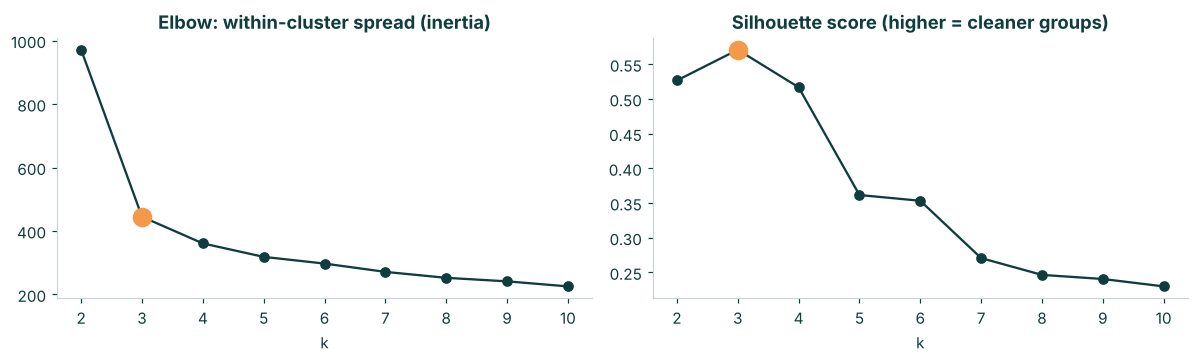

 k  inertia  silhouette
 2 971.1240      0.5266
 3 444.7337      0.5708
 4 360.7560      0.5168
 5 318.2917      0.3615
 6 297.1923      0.3532
 7 271.0120      0.2706
 8 252.2697      0.2464
 9 241.1848      0.2405
10 225.2688      0.2298

Best silhouette: k = 3 (0.5708)


In [6]:
scaler = StandardScaler().fit(diners[FEATURES])
X_seg = scaler.transform(diners[FEATURES])

scan = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_seg)
    scan.append({'k': k, 'inertia': km_k.inertia_, 'silhouette': silhouette_score(X_seg, km_k.labels_)})
scan = pd.DataFrame(scan)
best_k = int(scan.loc[scan.silhouette.idxmax(), 'k'])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(scan.k, scan.inertia, marker='o', color=INK)
axes[0].scatter([best_k], scan.loc[scan.k == best_k, 'inertia'], s=140, color=ACCENT, zorder=3)
axes[0].set_title("Elbow: within-cluster spread (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(scan.k, scan.silhouette, marker='o', color=INK)
axes[1].scatter([best_k], scan.silhouette.max(), s=140, color=ACCENT, zorder=3)
axes[1].set_title("Silhouette score (higher = cleaner groups)"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print(scan.round(4).to_string(index=False))
print(f"\nBest silhouette: k = {best_k} ({scan.silhouette.max():.4f})")

**Choosing k:** both methods point to **k = 3**.
- **Elbow:** inertia drops sharply from k=2 to k=3 (971 → 445) and only slowly after that. The bend is at 3.
- **Silhouette:** k=3 scores highest (0.571). Above 0.5 means diners sit clearly closer to their own group than to the next one. From k=5 on, the score falls below 0.37, so extra segments would split real groups apart.

In [7]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_seg)
diners['cluster'] = kmeans.labels_

profile = diners.groupby('cluster')[FEATURES + ['age', 'total_spend', TARGET]].mean()
profile['diners'] = diners.cluster.value_counts().sort_index()

# Name segments by RULE from the profile, not by hard-coded cluster numbers
names = {}
names[int(profile['discount_rate'].idxmax())] = 'Budget students'      # heaviest discount users
names[int(profile['avg_items_per_order'].idxmax())] = 'Families'       # biggest baskets
remaining = [c for c in profile.index if c not in names]
assert len(remaining) == 1, "naming rules collided"
names[int(remaining[0])] = 'Premium foodies'                           # the rest: lowest discount use, highest spend
segment_names = {int(k): v for k, v in sorted(names.items())}
diners['segment'] = diners.cluster.map(segment_names)
print("segment_names =", segment_names)

prof = profile.rename(index=segment_names)
prof.round(2)

segment_names = {0: 'Families', 1: 'Budget students', 2: 'Premium foodies'}


,orders_per_month,avg_order_value,avg_items_per_order,days_since_last_order,discount_rate,age,total_spend,reordered,diners
cluster,,,,,,,,,
Families,3.63,173.91,5.98,18.13,0.31,40.23,625.40,0.15,150
Budget students,13.10,42.13,1.99,5.00,0.62,22.33,554.46,0.98,200
Premium foodies,9.02,96.67,2.98,11.30,0.10,32.51,879.88,0.52,130


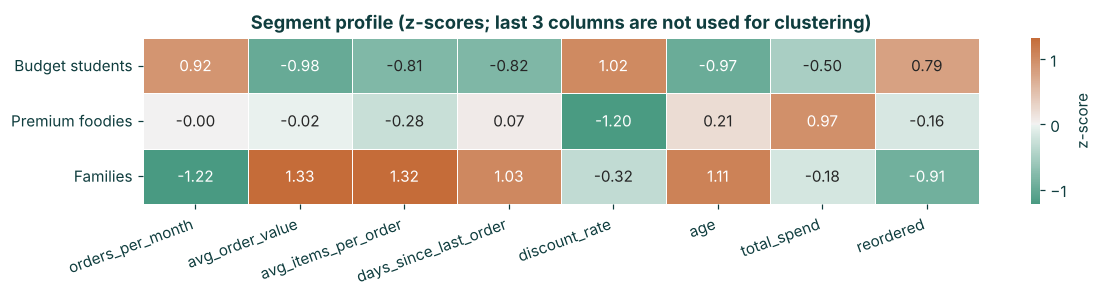

Budget students  (1123 baskets): cola 90%, fries 70%, burger 43%, wrap 23%
Premium foodies  (553 baskets): salad 67%, sushi 45%, coffee 42%, wine 27%, steak 24%, green_tea 24%
Families         (304 baskets): dessert 68%, pizza 45%, biryani 45%, raita 45%, pasta 25%, salad 21%


In [8]:
# z-score heatmap: how far each segment's average sits from the overall average, in standard deviations
z = pd.DataFrame(X_seg, columns=FEATURES).groupby(diners.segment).mean()
extra = diners.groupby('segment')[['age', 'total_spend', TARGET]].mean()
extra_z = (extra - diners[['age', 'total_spend', TARGET]].mean()) / diners[['age', 'total_spend', TARGET]].std(ddof=0)
heat = pd.concat([z, extra_z], axis=1)
order = ['Budget students', 'Premium foodies', 'Families']
fig, ax = plt.subplots(figsize=(11, 2.8))
sns.heatmap(heat.loc[order], annot=True, fmt='.2f', cmap=sns.diverging_palette(160, 30, s=80, l=55, as_cmap=True),
            center=0, cbar_kws={'label': 'z-score'}, ax=ax, linewidths=.5)
ax.set_title("Segment profile (z-scores; last 3 columns are not used for clustering)"); ax.set_ylabel("")
plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

# Top items per segment = share of that segment's baskets containing the item
seg_orders = orders.merge(diners[['diner_id', 'segment']], on='diner_id')
seg_baskets = seg_orders.groupby('segment').order_id.nunique()
item_share = (seg_orders.groupby(['segment', 'item']).order_id.nunique()
              .div(seg_baskets, level='segment').rename('share').reset_index())
top_items = (item_share.sort_values(['segment', 'share', 'item'], ascending=[True, False, True])
             .groupby('segment').head(6))
for s in order:
    t = top_items[top_items.segment == s]
    print(f"{s:16s} ({seg_baskets[s]} baskets): " + ", ".join(f"{r.item} {r.share:.0%}" for r in t.itertuples()))

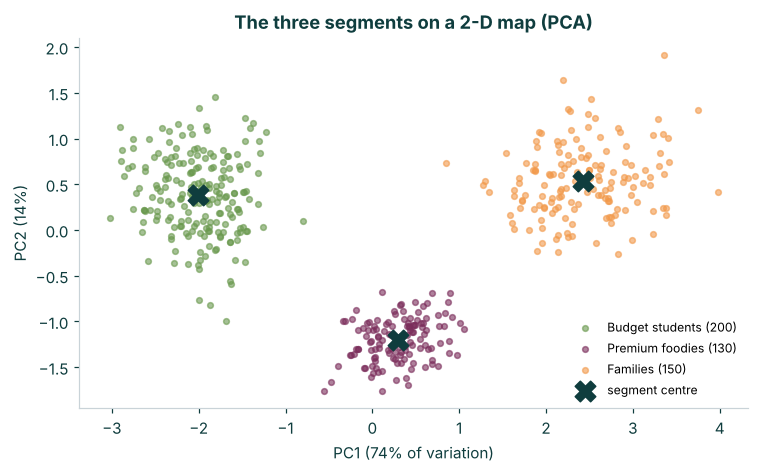

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_seg)
P = pca.transform(X_seg)
fig, ax = plt.subplots(figsize=(7, 4.4))
for s in order:
    m = diners.segment == s
    ax.scatter(P[m, 0], P[m, 1], s=14, alpha=.6, color=SEG_COLORS[s], label=f"{s} ({m.sum()})")
C = pca.transform(kmeans.cluster_centers_)
ax.scatter(C[:, 0], C[:, 1], marker='X', s=180, color=INK, label='segment centre')
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("The three segments on a 2-D map (PCA)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**The three segments, in business terms:**

| Segment | Size | Behaviour | What they order | Reorder rate |
|---|---|---|---|---|
| **Budget students** | 200 | Order often (about 13×/month), small cheap baskets (about AED 42, 2 items), use discounts on about 62% of orders, ordered about 5 days ago, average age 22 | cola, fries, burger, wrap | **98%** |
| **Premium foodies** | 130 | About 9 orders/month at about AED 97 with 3 items, rarely use discounts (10%), **highest monthly spend**, average age 33 | salad, sushi, coffee, wine, steak, green tea | **52%** |
| **Families** | 150 | Order rarely (about 4×/month) but big baskets (6 items, about AED 174), last ordered about 18 days ago, average age 40 | dessert, pizza, biryani, raita, pasta | **15%** |

Names are assigned by rule: the group with the heaviest discount use becomes *Budget students*, the one with the biggest baskets becomes *Families*, and the remaining group (lowest discount use, highest spend) becomes *Premium foodies*. If the cluster numbers changed on a re-run, the names would still land on the right groups.

## Part 2: What do they order together? (market-basket analysis)

Each `order_id` is one basket. I one-hot encode the baskets (one row per order, one True/False column per item) and run **Apriori**. For each rule *A → B*:
- **support**: the share of all baskets that contain A and B together (how common the combination is)
- **confidence**: of the baskets that contain A, the share that also contain B (how reliable the rule is)
- **lift**: confidence ÷ how common B is anyway. A lift of 1 means no link; a lift of 3 means B is 3× more likely when A is in the basket.

A rule and its mirror (A → B and B → A) have the same lift, so I keep only the more confident direction.

In [10]:
MIN_SUPPORT = 0.02

def assoc_rules(freq, n_baskets, min_lift=1.0):
    # Works on old and new mlxtend: newer versions require num_itemsets
    if 'num_itemsets' in inspect.signature(association_rules).parameters:
        return association_rules(freq, metric='lift', min_threshold=min_lift, num_itemsets=n_baskets)
    return association_rules(freq, metric='lift', min_threshold=min_lift)

def mine_rules(order_rows, min_support=MIN_SUPPORT):
    baskets = order_rows.groupby('order_id')['item'].apply(list)
    te = TransactionEncoder()
    onehot = pd.DataFrame(te.fit_transform(baskets), columns=te.columns_)
    freq = apriori(onehot, min_support=min_support, use_colnames=True)
    rules = assoc_rules(freq, len(onehot))
    if rules.empty:
        return rules, len(onehot)
    rules['if_bought'] = rules.antecedents.apply(lambda s: ' + '.join(sorted(s)))
    rules['then_also'] = rules.consequents.apply(lambda s: ' + '.join(sorted(s)))
    # rank: lift (rounded so a rule and its mirror tie exactly), then confidence, support, name
    rules['_lift'] = rules.lift.round(10)
    rules = rules.sort_values(['_lift', 'confidence', 'support', 'if_bought', 'then_also'],
                              ascending=[False, False, False, True, True])
    # hide mirrored duplicates (A->B vs B->A): same pair of item-sets; keep the first (more confident) one
    rules['pair'] = [frozenset([frozenset(a), frozenset(c)]) for a, c in zip(rules.antecedents, rules.consequents)]
    rules = rules.drop_duplicates('pair').drop(columns=['pair', '_lift'])
    return rules.reset_index(drop=True), len(onehot)

SHOW = ['if_bought', 'then_also', 'support', 'confidence', 'lift']
rules_all, n_all = mine_rules(orders)
print(f"{n_all} baskets -> {len(rules_all)} rules with lift > 1 (min support {MIN_SUPPORT:.0%}, mirrors hidden)")
rules_all[SHOW].head(12).round(3)

1980 baskets -> 63 rules with lift > 1 (min support 2%, mirrors hidden)


,if_bought,then_also,support,confidence,lift
0,cola + dessert,garlic_bread,0.021,0.933,30.800
1,cola + pizza,garlic_bread,0.021,0.933,30.800
2,miso_soup + sushi,green_tea,0.055,0.915,13.834
3,miso_soup,green_tea,0.060,0.915,13.826
4,green_tea + sushi,miso_soup,0.055,0.900,13.814
5,biryani + salad,raita,0.026,0.945,13.765
6,dessert + pasta,pizza,0.033,0.943,13.627
7,dessert + raita,biryani,0.029,0.919,13.385
8,biryani,raita,0.062,0.897,13.060
9,salad + steak,wine,0.060,0.967,13.028


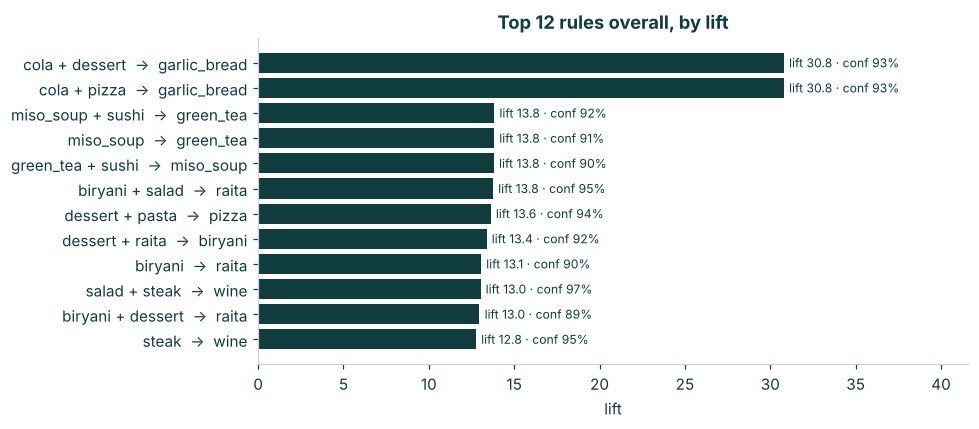

In [11]:
top = rules_all.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top.if_bought + "  →  " + top.then_also, top.lift, color=INK)
for i, (l, c) in enumerate(zip(top.lift, top.confidence)):
    ax.text(l + .3, i, f"lift {l:.1f} · conf {c:.0%}", va='center', fontsize=8, color=INK)
ax.set_xlabel("lift"); ax.set_title("Top 12 rules overall, by lift"); ax.set_xlim(0, top.lift.max() * 1.35)
plt.tight_layout(); plt.show()

**The top rules in business terms:**
1. **cola + dessert → garlic bread** and **cola + pizza → garlic bread** (lift about 31, confidence 93%). When a pizza or dessert order includes a cola, garlic bread is almost always in it too. This is a **"pizza night" bundle**: pizza + garlic bread + dessert + cola. Garlic bread is rare overall (3% of baskets), which is why the lift is so high.
2. **miso soup + sushi → green tea** (lift about 14, confidence 92%). Sushi with miso soup comes with green tea, which makes a natural **Japanese set**. Close behind: **biryani → raita** (90%) and **steak → wine** (95%). Each pairing is reliable enough to sell as one menu item.

**Promote:** the pizza-night bundle (pizza + garlic bread + dessert + cola) and the sushi set (sushi + miso soup + green tea), each at one bundle price.

In [12]:
seg_rules = {}
for s in order:
    rows = seg_orders[seg_orders.segment == s]
    r, n = mine_rules(rows)
    seg_rules[s] = (r, n)
    print(f"\n=== {s}: {n} baskets, {len(r)} rules ===")
    print(r[SHOW].head(6).round(3).to_string(index=False) if len(r) else "no rules")


=== Budget students: 1123 baskets, 5 rules ===
   if_bought    then_also  support  confidence  lift
        wrap cola + fries    0.191       0.820 1.302
 cola + wrap        fries    0.191       0.911 1.298
        wrap        fries    0.210       0.904 1.289
fries + wrap         cola    0.191       0.907 1.002
      burger         cola    0.390       0.905 1.000

=== Premium foodies: 553 baskets, 22 rules ===
        if_bought    then_also  support  confidence  lift
miso_soup + sushi    green_tea    0.195       0.915 3.864
        miso_soup    green_tea    0.213       0.915 3.861
green_tea + sushi    miso_soup    0.195       0.900 3.858
    salad + steak         wine    0.213       0.967 3.639
            steak         wine    0.230       0.948 3.565
            steak salad + wine    0.213       0.881 3.555

=== Families: 304 baskets, 38 rules ===
             if_bought            then_also  support  confidence  lift
cola + dessert + pizza         garlic_bread    0.115       0.946 4.7

In [13]:
# Why are overall lifts inflated?  Compare one rule overall vs inside its own segment.
def rule_stats(order_rows, a, c):
    b = order_rows.groupby('order_id')['item'].apply(set)
    n, has_a, has_c = len(b), b.apply(lambda s: a <= s), b.apply(lambda s: c <= s)
    conf = (has_a & has_c).sum() / has_a.sum()
    return dict(baskets=n, base_rate_of_consequent=has_c.mean(), confidence=conf, lift=conf / has_c.mean())

cmp = []
for a, c, s in [({'miso_soup'}, {'green_tea'}, 'Premium foodies'), ({'biryani'}, {'raita'}, 'Families'),
                ({'steak'}, {'wine'}, 'Premium foodies'), ({'pizza'}, {'dessert'}, 'Families')]:
    lab = f"{'+'.join(sorted(a))} -> {'+'.join(sorted(c))}"
    cmp.append({'rule': lab, 'scope': 'Overall', **rule_stats(orders, a, c)})
    cmp.append({'rule': lab, 'scope': s, **rule_stats(seg_orders[seg_orders.segment == s], a, c)})
pd.DataFrame(cmp).round(3)

,rule,scope,baskets,base_rate_of_consequent,confidence,lift
0,miso_soup -> green_tea,Overall,1980,0.066,0.915,13.826
1,miso_soup -> green_tea,Premium foodies,553,0.237,0.915,3.861
2,biryani -> raita,Overall,1980,0.069,0.897,13.060
3,biryani -> raita,Families,304,0.447,0.897,2.005
4,steak -> wine,Overall,1980,0.074,0.948,12.766
5,steak -> wine,Premium foodies,553,0.266,0.948,3.565
6,pizza -> dessert,Overall,1980,0.105,0.898,8.588
7,pizza -> dessert,Families,304,0.681,0.898,1.319


**Do segments order differently? Very much so.** The three segments barely share a menu:
- **Families**: pizza night (cola + pizza + dessert → garlic bread, lift about 4.8 within the segment), plus biryani with raita and dessert.
- **Premium foodies**: miso soup → green tea (about 3.9), steak → wine (about 3.6), salad + sushi → coffee (about 2.2).
- **Budget students**: only 4 items (cola, fries, burger, wrap), and the rules are weak (wrap → fries, lift about 1.3). Cola is in about 90% of their baskets, so "anything → cola" has a lift of about 1.0 and tells us nothing new. Students simply order a fixed combo.

**Why the overall lifts are inflated:** lift divides by how common the consequent is *across all baskets*. Green tea is in only 6.6% of all baskets, because students and families never order it. Inside the foodie segment it is in 23.7%. So the overall lift (13.8) mixes two effects: "miso-soup buyers like green tea" **and** "both items belong to the foodie menu". The within-segment lift (3.9) measures only the true pairing. When each segment eats from its own menu, pooled lifts overstate how strong the pairings are. Bundles should be sized from the **segment-level** numbers.

## Part 3: Who will come back? (reorder classifier)

Inputs: the 5 behaviour features + `age` + `total_spend` (7 inputs, in the order `app.py` sends them). I hold back 25% of diners as a test set, **stratified** so it keeps the 60/40 mix, and compare five models using 5-fold cross-validation on the training set only.

In [14]:
X = diners[CLF_INPUTS]; y = diners[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"train {len(X_tr)} | test {len(X_te)} (churners in test: {(y_te == 0).sum()}, reorderers: {(y_te == 1).sum()})")

models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Logistic regression (balanced)': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Decision tree': DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    'Random forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    'Gradient boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
test_baseline = (y_te == 1).mean()

rows, fitted = [], {}
for name, model in models.items():
    cvres = cross_validate(model, X_tr, y_tr, cv=cv5, scoring=['accuracy', 'roc_auc'])
    model.fit(X_tr, y_tr); fitted[name] = model
    pred = model.predict(X_te); proba = model.predict_proba(X_te)[:, 1]
    cm = confusion_matrix(y_te, pred, labels=[0, 1])
    rows.append({'model': name, 'CV accuracy': cvres['test_accuracy'].mean(), 'CV ROC-AUC': cvres['test_roc_auc'].mean(),
                 'test accuracy': accuracy_score(y_te, pred), 'test ROC-AUC': roc_auc_score(y_te, proba),
                 'churners caught': f"{cm[0,0]}/{cm[0].sum()}", 'missed churners': cm[0, 1], 'false alarms': cm[1, 0]})
results = pd.DataFrame(rows).set_index('model')
print(f"Baseline (always 'reorder') on the test set: {test_baseline:.1%}")
results.round(3)

train 360 | test 120 (churners in test: 48, reorderers: 72)


Baseline (always 'reorder') on the test set: 60.0%


,CV accuracy,CV ROC-AUC,test accuracy,test ROC-AUC,churners caught,missed churners,false alarms
model,,,,,,,
Logistic regression,0.861,0.941,0.858,0.961,40/48,8,9
Logistic regression (balanced),0.850,0.940,0.858,0.960,44/48,4,13
Decision tree,0.833,0.885,0.842,0.871,38/48,10,9
Random forest,0.861,0.926,0.867,0.928,41/48,7,9
Gradient boosting,0.842,0.928,0.842,0.918,38/48,10,9


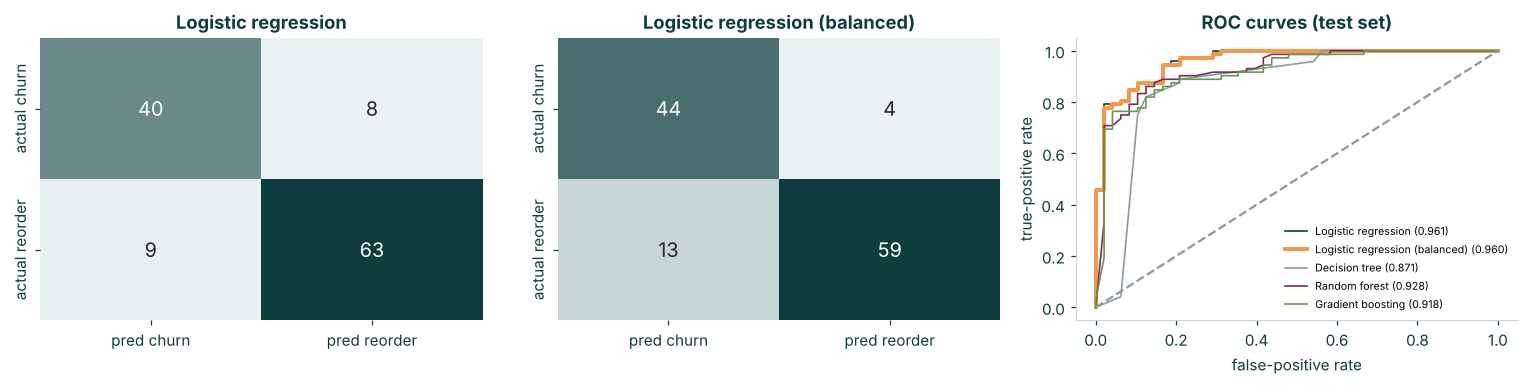

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, name in zip(axes[:2], ['Logistic regression', 'Logistic regression (balanced)']):
    cm = confusion_matrix(y_te, fitted[name].predict(X_te), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap=sns.light_palette(INK, as_cmap=True), ax=ax,
                xticklabels=['pred churn', 'pred reorder'], yticklabels=['actual churn', 'actual reorder'],
                annot_kws={'size': 13})
    ax.set_title(name)
for name, model in fitted.items():
    fpr, tpr, _ = roc_curve(y_te, model.predict_proba(X_te)[:, 1])
    axes[2].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]):.3f})",
                 color={'Logistic regression': INK, 'Logistic regression (balanced)': ACCENT, 'Decision tree': MUTED,
                        'Random forest': '#7B2D5B', 'Gradient boosting': '#6A994E'}[name],
                 lw=2.6 if 'balanced' in name else 1.1)
axes[2].plot([0, 1], [0, 1], ls='--', color=MUTED); axes[2].legend(fontsize=7, frameon=False)
axes[2].set_title("ROC curves (test set)"); axes[2].set_xlabel("false-positive rate"); axes[2].set_ylabel("true-positive rate")
plt.tight_layout(); plt.show()

### Which mistake costs more?

- **Missed churner** (the model says "will reorder" but the diner leaves): QuickBite loses that diner's future orders. The average churner was spending about **AED 700 a month** (computed below).
- **False alarm** (the model says "at risk" but the diner would have reordered anyway): QuickBite sends a win-back voucher it didn't need to. Say **AED 20**.

A missed churner costs roughly **35× more** than a wasted voucher, so the model should be chosen for **catching churners**, even at the price of some extra vouchers. I put a cost on each model's test-set mistakes below.

In [16]:
VOUCHER_COST = 20
monthly_value = diners.orders_per_month * diners.avg_order_value
LOST_DINER_COST = 700
print(f"Average monthly order value of a churner: AED {monthly_value[diners[TARGET] == 0].mean():.0f} -> use AED {LOST_DINER_COST}")
cost = results[['test accuracy', 'churners caught', 'missed churners', 'false alarms']].copy()
cost['cost of mistakes (AED)'] = cost['missed churners'] * LOST_DINER_COST + cost['false alarms'] * VOUCHER_COST
cost.sort_values('cost of mistakes (AED)').round(3)

Average monthly order value of a churner: AED 707 -> use AED 700


,test accuracy,churners caught,missed churners,false alarms,cost of mistakes (AED)
model,,,,,
Logistic regression (balanced),0.858,44/48,4,13,3060
Random forest,0.867,41/48,7,9,5080
Logistic regression,0.858,40/48,8,9,5780
Decision tree,0.842,38/48,10,9,7180
Gradient boosting,0.842,38/48,10,9,7180


**Choice: logistic regression with `class_weight='balanced'`.**
- Its test accuracy is **85.8%**, against a 60% baseline. Cross-validated accuracy (85.0%) and ROC-AUC (0.94) on the training set agree, so the test result isn't a lucky split.
- It catches **44 of the 48 churners** in the test set, more than any other model, and has the **lowest cost of mistakes**. The price is 13 false alarms (loyal diners who get a voucher anyway), which is cheap.
- It is also easy to explain: each input has one weight, and the dashboard can rebuild the model exactly from those weights.

**Kind of errors:** it rarely misses a churner (4 of 48). Its errors lean towards false alarms, which is the safer direction for QuickBite.

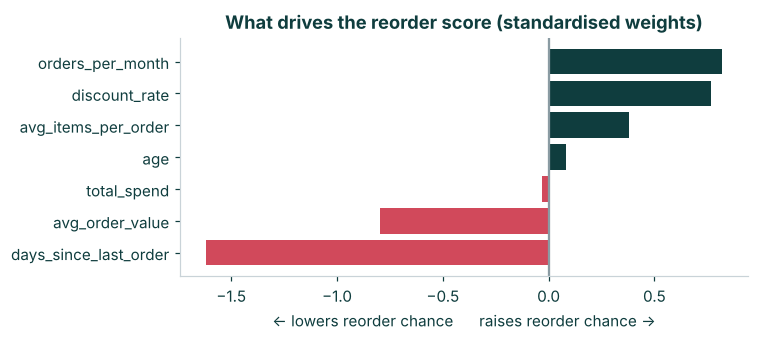

days_since_last_order   -1.620
avg_order_value         -0.798
total_spend             -0.030
age                      0.081
avg_items_per_order      0.381
discount_rate            0.766
orders_per_month         0.820


In [17]:
clf = fitted['Logistic regression (balanced)']
lr = clf.named_steps['logisticregression']
drivers = pd.Series(lr.coef_[0], index=CLF_INPUTS).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(drivers.index, drivers.values, color=[RED if v < 0 else INK for v in drivers.values])
ax.axvline(0, color=MUTED); ax.set_title("What drives the reorder score (standardised weights)")
ax.set_xlabel("← lowers reorder chance      raises reorder chance →")
plt.tight_layout(); plt.show()
print(drivers.round(3).to_string())

In [18]:
te = diners.loc[X_te.index, ['segment', TARGET]].copy()
te['pred'] = clf.predict(X_te)
te['error'] = np.select([(te[TARGET] == 0) & (te.pred == 1), (te[TARGET] == 1) & (te.pred == 0)],
                        ['missed churner', 'false alarm'], 'correct')
pd.crosstab(te.segment, te.error, margins=True)

error,correct,false alarm,missed churner,All
segment,,,,
Budget students,48,0,1,49
Families,37,1,0,38
Premium foodies,18,12,3,33
All,103,13,4,120


**Reading the drivers:** **days since last order** has by far the biggest weight (−1.62). The longer since the last order, the less likely a reorder. **Orders per month** (+0.82) and **discount use** (+0.77) push the score up, while a high **order value** (−0.80) pulls it down, which is the Families pattern of rare, big orders. Age and `total_spend` barely matter once the others are known (`total_spend` is about one month of spend; see Part 0). Several of these weights partly reflect *which segment* a diner belongs to; the discount check in Part 6 separates the two.

**Where the errors fall:** 15 of the 17 mistakes are among **Premium foodies**, the 52/48 segment where the outcome is genuinely uncertain. Students (98% reorder) and Families (15% reorder) are easy calls, with one error each.

## Part 4: Save the models for the dashboard

`app.py` expects a dictionary with exactly six keys. `reco` maps each segment name to its top 5 items by share of that segment's baskets. Students only ever order 4 items, so their list has 4.

In [19]:
reco = {s: (item_share[item_share.segment == s].sort_values(['share', 'item'], ascending=[False, True])
            .item.head(5).tolist()) for s in segment_names.values()}
food_models = {'scaler': scaler, 'kmeans': kmeans, 'segment_names': segment_names,
               'clf': clf, 'features': FEATURES, 'reco': reco}
joblib.dump(food_models, 'food_models.joblib')
M = joblib.load('food_models.joblib')
print("keys:", list(M.keys()))
print("segment_names:", M['segment_names'])
for k, v in M['reco'].items():
    print(f"reco[{k!r}] = {v}")

keys: ['scaler', 'kmeans', 'segment_names', 'clf', 'features', 'reco']
segment_names: {0: 'Families', 1: 'Budget students', 2: 'Premium foodies'}
reco['Families'] = ['dessert', 'pizza', 'biryani', 'raita', 'pasta']
reco['Budget students'] = ['cola', 'fries', 'burger', 'wrap']
reco['Premium foodies'] = ['salad', 'sushi', 'coffee', 'wine', 'steak']


In [20]:
# Same logic as analyse() in app.py
def analyse(profile, M=M):
    row = pd.DataFrame([profile])
    seg = int(M['kmeans'].predict(M['scaler'].transform(row[M['features']]))[0])
    name = M['segment_names'].get(seg, f"Segment {seg}")
    Xrow = row[M['features'] + ['age', 'total_spend']]
    return name, int(M['clf'].predict(Xrow)[0]), float(M['clf'].predict_proba(Xrow)[0][1]), M['reco'].get(name, [])

PERSONAS = {
    'Aisha, uni student':        dict(age=21, orders_per_month=14, avg_order_value=40,  avg_items_per_order=2, days_since_last_order=3,  discount_rate=0.70, total_spend=560),
    'The Khans, family of five': dict(age=41, orders_per_month=4,  avg_order_value=180, avg_items_per_order=6, days_since_last_order=20, discount_rate=0.30, total_spend=700),
    'Omar, busy consultant':     dict(age=33, orders_per_month=9,  avg_order_value=100, avg_items_per_order=3, days_since_last_order=8,  discount_rate=0.10, total_spend=900),
    'Lena, foodie drifting off': dict(age=34, orders_per_month=8,  avg_order_value=105, avg_items_per_order=3, days_since_last_order=16, discount_rate=0.08, total_spend=850),
    'The Raos, regular family':  dict(age=38, orders_per_month=5,  avg_order_value=160, avg_items_per_order=6, days_since_last_order=6,  discount_rate=0.25, total_spend=800),
}
out = []
for who, p in PERSONAS.items():
    name, reorder, prob, items = analyse(p)
    out.append({'persona': who, 'segment': name, 'verdict': 'Yes' if reorder else 'At risk',
                'reorder chance': f"{prob*100:.0f}%", 'recommended': ' · '.join(items)})
pd.DataFrame(out).set_index('persona')

,segment,verdict,reorder chance,recommended
persona,,,,
"Aisha, uni student",Budget students,Yes,99%,cola · fries · burger · wrap
"The Khans, family of five",Families,At risk,4%,dessert · pizza · biryani · raita · pasta
"Omar, busy consultant",Premium foodies,Yes,58%,salad · sushi · coffee · wine · steak
"Lena, foodie drifting off",Premium foodies,At risk,14%,salad · sushi · coffee · wine · steak
"The Raos, regular family",Families,Yes,59%,dessert · pizza · biryani · raita · pasta


In [21]:
# Confirm the provided app.py runs UNCHANGED with this file (Streamlit's headless test runner)
import logging
from streamlit.testing.v1 import AppTest
for _n in [n for n in logging.root.manager.loggerDict if n.startswith('streamlit')]:
    logging.getLogger(_n).setLevel(logging.ERROR)   # silence 'bare mode' warnings
print("app.py md5:", hashlib.md5(open('app.py', 'rb').read()).hexdigest(), "(original: ea7999344d51e9d656133d89cc25c6a3)")
at = AppTest.from_file(os.path.abspath('app.py'), default_timeout=60).run()
print("exceptions:", list(at.exception))
print("default profile ->", [(m.label, m.value, m.delta) for m in at.metric])
# drive the sliders to a churn-risk family profile
p = PERSONAS['The Khans, family of five']
for s, v in zip(at.sidebar.slider, [p['age'], p['orders_per_month'], p['avg_order_value'], p['avg_items_per_order'],
                                    p['days_since_last_order'], p['discount_rate']]):
    s.set_value(v)
at.sidebar.number_input[0].set_value(p['total_spend'])
at.run()
print("The Khans ->", [(m.label, m.value, m.delta) for m in at.metric])
print("recommended:", [m.value for m in at.markdown if '·' in m.value])
print("info box:", [i.value for i in at.info])

app.py md5: ea7999344d51e9d656133d89cc25c6a3 (original: ea7999344d51e9d656133d89cc25c6a3)


exceptions: []
default profile -> [('Diner Segment', 'Premium foodies', ''), ('Will Reorder?', 'Yes ✅', '61% likely')]
The Khans -> [('Diner Segment', 'Families', ''), ('Will Reorder?', 'At risk ⚠️', '4% likely')]
recommended: ['dessert · pizza · biryani · raita · pasta']
info box: ['This diner looks **at risk of churning** — a win-back offer on their favourite items could help.']


The dashboard loads `food_models.joblib` without any change to `app.py` and returns segment, reorder verdict, probability and recommended items. To run it yourself: `streamlit run app.py`.

## Part 5: Deeper findings

### F1: One rule nearly matches the model

Recency had the biggest weight in the classifier. How far does it get **on its own**? I find the best single cut-off on `days_since_last_order` with a depth-1 decision tree and compare it, using 5-fold cross-validation on all 480 diners, with the full 7-input model and with a 2-input model (recency + segment).

In [22]:
y_all = diners[TARGET]
stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE).fit(diners[['days_since_last_order']], y_all)
cut = stump.tree_.threshold[0]
print(f"Best single cut-off: days_since_last_order <= {cut:.1f}  ->  predict 'reorder' (i.e. ordered within {int(cut)} days)")

seg_dummies = pd.get_dummies(diners.segment, prefix='seg').astype(int)
X_rec_seg = pd.concat([diners[['days_since_last_order']], seg_dummies], axis=1)
lr_plain = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr_bal = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced'))
cands = {
    'Recency rule (1 cut-off)': (DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE), diners[['days_since_last_order']]),
    'Full model, 7 inputs (balanced LR, chosen)': (lr_bal, diners[CLF_INPUTS]),
    'Full model, 7 inputs (plain LR)': (lr_plain, diners[CLF_INPUTS]),
    'Recency + segment (plain LR)': (lr_plain, X_rec_seg),
    'Recency + segment (balanced LR)': (lr_bal, X_rec_seg),
}
f1 = pd.DataFrame({n: {'5-fold CV accuracy': cross_val_score(m, Xc, y_all, cv=cv5).mean(),
                       '5-fold CV ROC-AUC': cross_val_score(m, Xc, y_all, cv=cv5, scoring='roc_auc').mean()}
                   for n, (m, Xc) in cands.items()}).T
f1.round(3)

Best single cut-off: days_since_last_order <= 11.5  ->  predict 'reorder' (i.e. ordered within 11 days)


,5-fold CV accuracy,5-fold CV ROC-AUC
Recency rule (1 cut-off),0.852,0.840
"Full model, 7 inputs (balanced LR, chosen)",0.858,0.941
"Full model, 7 inputs (plain LR)",0.858,0.941
Recency + segment (plain LR),0.867,0.936
Recency + segment (balanced LR),0.858,0.936


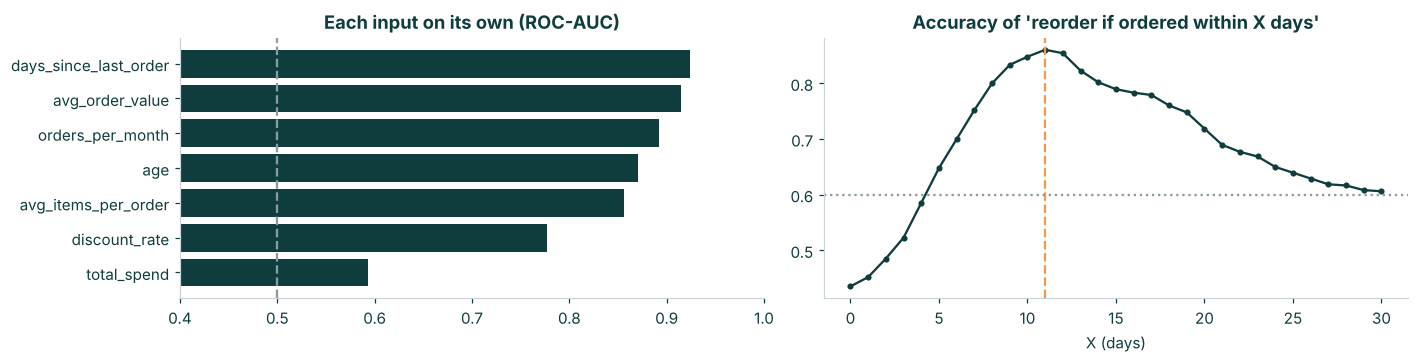

,ROC-AUC alone,direction
days_since_last_order,0.923783,lower -> reorders
avg_order_value,0.914289,lower -> reorders
orders_per_month,0.892334,higher -> reorders
age,0.87103,lower -> reorders
avg_items_per_order,0.855966,lower -> reorders
discount_rate,0.77757,higher -> reorders
total_spend,0.592683,lower -> reorders


In [23]:
auc1 = {}
for f in CLF_INPUTS:
    a = roc_auc_score(y_all, diners[f])
    auc1[f] = (max(a, 1 - a), 'higher -> reorders' if a > .5 else 'lower -> reorders')
auc1 = pd.DataFrame(auc1, index=['ROC-AUC alone', 'direction']).T.sort_values('ROC-AUC alone', ascending=False)

cuts = np.arange(0, 31)
acc_by_cut = [((diners.days_since_last_order <= c).astype(int) == y_all).mean() for c in cuts]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
axes[0].barh(auc1.index[::-1], auc1['ROC-AUC alone'][::-1].astype(float), color=INK)
axes[0].axvline(.5, color=MUTED, ls='--'); axes[0].set_xlim(.4, 1); axes[0].set_title("Each input on its own (ROC-AUC)")
axes[1].plot(cuts, acc_by_cut, marker='o', ms=3, color=INK)
axes[1].axvline(int(cut), color=ACCENT, ls='--'); axes[1].axhline(baseline, color=MUTED, ls=':')
axes[1].set_title("Accuracy of 'reorder if ordered within X days'"); axes[1].set_xlabel("X (days)")
plt.tight_layout(); plt.show()
auc1

**Finding:** one plain rule, *"if they ordered in the last 11 days they'll reorder"*, scores **85.2%** cross-validated accuracy. The full 7-input model reaches **85.8%** and recency + segment reaches **86.7%** (plain logistic regression). That's only about one point better. Recency alone has a ROC-AUC of **0.92**, the highest of any input.

**The data-leakage question:** this is suspicious. If `days_since_last_order` was measured **after** the window in which `reordered` was recorded, then a diner who reordered has, by definition, a recent last order. In that case the model is partly reading the answer off the input, and real-world accuracy would be lower. QuickBite should confirm that both columns come from the same snapshot date, with `reordered` measured *afterwards*. Until then, read the 86% as an upper bound. Either way, the operational lesson holds: **recency is the early-warning signal to watch.**

### F2: Each segment has its own churn clock

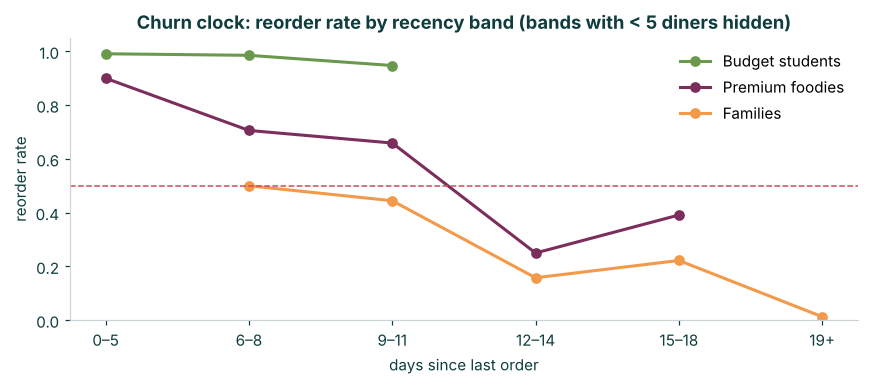

,Budget students,Premium foodies,Families
band,,,
0–5,99.1% (n=112),90.0% (n=10),hidden (n=1)
6–8,98.5% (n=68),70.6% (n=17),50.0% (n=8)
9–11,94.7% (n=19),65.9% (n=44),44.4% (n=18)
12–14,hidden (n=1),25.0% (n=32),15.8% (n=19)
15–18,hidden (n=0),39.1% (n=23),22.2% (n=27)
19+,hidden (n=0),hidden (n=4),1.3% (n=77)


Budget students : never falls to 50% in any band with >= 5 diners (max recency seen: 12 days) -> no win-back trigger needed
Premium foodies : reorder rate first falls to 50% or below in the 12-day band -> send the win-back offer by day 12
Families        : reorder rate first falls to 50% or below in the 6-day band -> send the win-back offer by day 6


In [24]:
BANDS = [(0, 5), (6, 8), (9, 11), (12, 14), (15, 18), (19, 999)]
band_label = lambda a, b: f"{a}–{b}" if b < 999 else f"{a}+"
MIN_N = 5
clock_rows, trigger = [], {}
for s in order:
    sd = diners[diners.segment == s]
    trigger[s] = None
    for a, b in BANDS:
        sub = sd[sd.days_since_last_order.between(a, b)]
        rate = sub[TARGET].mean() if len(sub) else np.nan
        shown = len(sub) >= MIN_N
        clock_rows.append({'segment': s, 'band': band_label(a, b), 'diners': len(sub),
                           'reorder rate': rate if shown else np.nan})
        if shown and trigger[s] is None and rate <= 0.5:
            trigger[s] = a
clock = pd.DataFrame(clock_rows)
table = clock.pivot(index='band', columns='segment', values='reorder rate').reindex([band_label(a, b) for a, b in BANDS])[order]
counts = clock.pivot(index='band', columns='segment', values='diners').reindex(table.index)[order]
fig, ax = plt.subplots(figsize=(8, 3.6))
for s in order:
    ax.plot(table.index, table[s], marker='o', color=SEG_COLORS[s], label=s, lw=2)
ax.axhline(.5, color=RED, ls='--', lw=1); ax.set_ylim(0, 1.05)
ax.set_ylabel("reorder rate"); ax.set_xlabel("days since last order")
ax.set_title("Churn clock: reorder rate by recency band (bands with < 5 diners hidden)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
display(pd.DataFrame({s: [f"{table.loc[b, s]*100:.1f}%  (n={int(counts.loc[b, s])})" if pd.notna(table.loc[b, s])
                          else f"hidden (n={int(counts.loc[b, s])})" for b in table.index] for s in order}, index=table.index))
for s in order:
    print(f"{s:16s}: " + (f"reorder rate first falls to 50% or below in the {trigger[s]}-day band -> send the win-back offer by day {trigger[s]}"
                          if trigger[s] is not None else
                          f"never falls to 50% in any band with >= {MIN_N} diners (max recency seen: "
                          f"{diners[diners.segment == s].days_since_last_order.max()} days) -> no win-back trigger needed"))

**Finding:** there is no single "at-risk" day. Each segment slips at a different point.
- **Families**: by days 6–8, only half of families reorder, so **send the win-back offer by day 6**. Families order about 4×/month (roughly every 8 days), so one late order is already a warning sign.
- **Premium foodies**: they hold up at 66–90% until day 11, then drop to 25% in the 12–14 band, so **send it by day 12**.
- **Budget students**: they stay above 94% in every band with enough diners (none has gone more than 12 days). No trigger is needed; a voucher would be wasted on them.

### F5: Segments are real, not a side-effect of recency

Recency drives reorders, and it is also one of the clustering features. Could the "segments" just be recency groups in disguise? To test this, I re-cluster with each feature dropped in turn and compare the result with the saved segments.

In [25]:
f5 = []
for drop in [None] + FEATURES:
    feats = [f for f in FEATURES if f != drop]
    Xd = StandardScaler().fit_transform(diners[feats])
    kd = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(Xd)
    f5.append({'dropped': drop or '(none: all 5)', 'silhouette': silhouette_score(Xd, kd.labels_),
               'ARI vs saved segments': adjusted_rand_score(diners.cluster, kd.labels_)})
    if drop == 'days_since_last_order':
        labels_no_recency = kd.labels_
f5 = pd.DataFrame(f5).set_index('dropped')
display(f5.round(4))
print("Crosstab: saved segments vs re-clustering WITHOUT recency")
pd.crosstab(diners.segment, pd.Series(labels_no_recency, name='new cluster (no recency)'))

,silhouette,ARI vs saved segments
dropped,,
(none: all 5),0.5708,1.0000
orders_per_month,0.5903,0.9946
avg_order_value,0.5415,1.0000
avg_items_per_order,0.5668,0.9946
days_since_last_order,0.6435,1.0000
discount_rate,0.4796,0.9447


Crosstab: saved segments vs re-clustering WITHOUT recency


new cluster (no recency),0,1,2
segment,,,
Budget students,0,200,0
Families,150,0,0
Premium foodies,0,0,130


**Finding:** dropping recency gives **exactly the same three segments** (adjusted Rand index = 1.0, a perfect match), and the groups become *cleaner* (silhouette rises from 0.571 to 0.643). The segments come from *what and how people order* (frequency, basket size, order value, discounts), not from how recently they ordered. Dropping any other single feature also leaves the segments almost unchanged (ARI ≥ 0.94). The segmentation is robust.

## Part 6: Business takeaway

In [26]:
diners['monthly_value'] = diners.orders_per_month * diners.avg_order_value
lost = (diners[diners[TARGET] == 0].groupby('segment')
        .agg(churners=('monthly_value', 'size'), monthly_value_lost=('monthly_value', 'sum')))
lost['share of segment'] = lost.churners / diners.segment.value_counts()
lost = lost.reindex(order)
display(lost.round(2))

disc = diners.groupby(['segment', TARGET]).discount_rate.mean().unstack().rename(columns={0: 'churners', 1: 'reorderers'})
disc['ROC-AUC of discount (within segment)'] = [
    roc_auc_score(diners[diners.segment == s][TARGET], diners[diners.segment == s].discount_rate) for s in disc.index]
disc['churners (n)'] = diners[diners[TARGET] == 0].segment.value_counts().reindex(disc.index)
print("Discount use: reorderers vs churners, overall:",
      diners.groupby(TARGET).discount_rate.mean().round(3).rename({0: 'churners', 1: 'reorderers'}).to_dict())
disc.reindex(order).round(3)

,churners,monthly_value_lost,share of segment
segment,,,
Budget students,3,1737.64,0.02
Premium foodies,62,54888.87,0.48
Families,127,79123.45,0.85


Discount use: reorderers vs churners, overall: {'churners': 0.239, 'reorderers': 0.475}


reordered,churners,reorderers,ROC-AUC of discount (within segment),churners (n)
segment,,,,
Budget students,0.630,0.618,0.453,3
Premium foodies,0.098,0.106,0.526,62
Families,0.298,0.347,0.675,127


**Takeaway for QuickBite:**

1. **Focus on Families.** 127 of 150 families churned, taking about **AED 79k of monthly orders** with them, the largest loss of any segment (Premium foodies about AED 55k; students only about AED 1.7k).
2. **Promote the "pizza night" bundle** (pizza + garlic bread + dessert + cola) to Families and the **sushi set** (sushi + miso soup + green tea) to Premium foodies. Both pairings hold up within their own segments, not just in the pooled data.
3. **Time the offers with the churn clock.** Send the win-back offer **by day 6 for Families and by day 12 for Premium foodies**. Students don't need one.
4. **Use the reorder model weekly.** Every Monday, score all diners, send the bundle voucher to anyone flagged "at risk" (it catches about 9 in 10 churners), and keep the cheap false alarms as the accepted price.
5. **Student discounts can probably be pulled back, carefully.** Reorderers overall use discounts twice as often (48% vs 24% of orders), but that is a *segment* effect: within students, discount use is the same for reorderers and churners (62% vs 63%), and 98% reorder regardless. Test a smaller student discount on a holdout group first, since there are only 3 student churners to learn from. For Families, reorderers use discounts a little *more* (35% vs 30%), so keep family offers.